# **Лабораторна робота 3**
**Програмування алгоритмів розгалуженої та циклічної структури**

**Мета:** Опанувати практичні навички алгоритмізації та проектування програм розгалуженої та циклічної структури мовою Python. Навчитися реалізовувати багатоваріантний вибір за допомогою повних і каскадних умовних конструкцій if-elif-else, застосовувати тернарні умовні вирази для оптимізації потоку керування, розробляти ітераційні алгоритми обчислення нескінченних числових рядів із заданою точністю
 за допомогою циклу з передумовою while з використанням рекурентних співвідношень, а також виконувати чисельне табулювання кусочно-неперервних функцій за допомогою параметричного циклу for та генератора діапазонів range().


**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

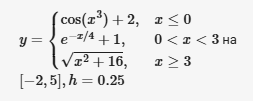

In [1]:
import math

def f(x):
    if x <= 0:
        return math.cos(x**3) + 2
    elif 0 < x < 3:
        return math.exp(-x / 4) + 1
    else:  # x >= 3
        return math.sqrt(x**2 + 16)

# Параметри табулювання: інтервал [-2, 5], крок h = 0.25
start = -2.0
stop = 5.0
h = 0.25

print(f"{'x':>7} | {'y':>12}")
print("-" * 22)

x = start
while x <= stop + 1e-9:
    y = f(x)
    print(f"{x:7.2f} | {y:12.6f}")
    x += h

      x |            y
----------------------
  -2.00 |     1.854500
  -1.75 |     2.602784
  -1.50 |     1.027116
  -1.25 |     1.626918
  -1.00 |     2.540302
  -0.75 |     2.912323
  -0.50 |     2.992198
  -0.25 |     2.999878
   0.00 |     3.000000
   0.25 |     1.939413
   0.50 |     1.882497
   0.75 |     1.829029
   1.00 |     1.778801
   1.25 |     1.731616
   1.50 |     1.687289
   1.75 |     1.645649
   2.00 |     1.606531
   2.25 |     1.569783
   2.50 |     1.535261
   2.75 |     1.502832
   3.00 |     5.000000
   3.25 |     5.153882
   3.50 |     5.315073
   3.75 |     5.482928
   4.00 |     5.656854
   4.25 |     5.836309
   4.50 |     6.020797
   4.75 |     6.209871
   5.00 |     6.403124


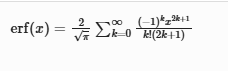

In [6]:
import math

def erf_series(x, eps=1e-10, max_iter=1000):
    if x == 0:
        return 0.0

    term = x
    total_sum = term
    x_sq = x * x

    for k in range(1, max_iter):
        # Рекурентне обчислення наступного члена ряду
        term *= -x_sq * (2 * k - 1) / (k * (2 * k + 1))
        total_sum += term

        if abs(term) < eps:
            break

    return (2.0 / math.sqrt(math.pi)) * total_sum

# Приклад виклику для різних значень x
test_values = [0.0, 0.5, 1.0, 1.5, 2.0]

print(f"{'x':>5} | {'Ряд Тейлора':>14} | {'math.erf':>14} | {'Різниця':>12}")
print("-" * 52)
for x in test_values:
    res_series = erf_series(x)
    res_math = math.erf(x)
    diff = abs(res_series - res_math)
    print(f"{x:5.2f} | {res_series:14.10f} | {res_math:14.10f} | {diff:12.2e}")

    x |    Ряд Тейлора |       math.erf |      Різниця
----------------------------------------------------
 0.00 |   0.0000000000 |   0.0000000000 |     0.00e+00
 0.50 |   0.5204998778 |   0.5204998778 |     3.05e-13
 1.00 |   0.8427007930 |   0.8427007929 |     6.29e-12
 1.50 |   0.9661051465 |   0.9661051465 |     1.58e-12
 2.00 |   0.9953222650 |   0.9953222650 |     2.80e-12


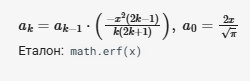

In [7]:
import math

def erf_recurrent(x, eps=1e-12, max_iter=1000):
    if x == 0:
        return 0.0

    # a_0 = 2x / sqrt(pi)
    a = (2.0 * x) / math.sqrt(math.pi)
    total_sum = a
    x_sq = x * x

    # a_k = a_{k-1} * (-x^2 * (2k - 1) / (k * (2k + 1)))
    for k in range(1, max_iter):
        a *= (-x_sq * (2 * k - 1)) / (k * (2 * k + 1))
        total_sum += a

        if abs(a) < eps:
            break

    return total_sum

# Порівняння з еталоном math.erf(x)
test_values = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]

print(f"{'x':>5} | {'erf (рекурентна)':>18} | {'math.erf(x)':>14} | {'Абс. похибка':>12}")
print("-" * 57)
for x in test_values:
    res = erf_recurrent(x)
    ref = math.erf(x)
    diff = abs(res - ref)
    print(f"{x:5.2f} | {res:18.12f} | {ref:14.12f} | {diff:12.2e}")

    x |   erf (рекурентна) |    math.erf(x) | Абс. похибка
---------------------------------------------------------
 0.00 |     0.000000000000 | 0.000000000000 |     0.00e+00
 0.25 |     0.276326390168 | 0.276326390168 |     1.11e-16
 0.50 |     0.520499877813 | 0.520499877813 |     6.88e-15
 1.00 |     0.842700792950 | 0.842700792950 |     2.62e-14
 1.50 |     0.966105146475 | 0.966105146475 |     1.74e-14
 2.00 |     0.995322265019 | 0.995322265019 |     5.97e-14


**Контрольні запитання**

1. Обчислення переривається, щойно результат відомий: False and ... не рахує праву частину, True or ... не рахує праву частину.Захист: у x != 0 and (1 / x) > 1 ділення не виконається при $x = 0$, запобігаючи ZeroDivisionError.
2. if-else (statement) — керівна конструкція без результату; не можна присвоїти змінній.Тернарний A if cond else B (expression) — вираз, що завжди повертає одне значення і вбудовується у присвоєння чи виклики.
3. Пряме обчислення $x^k$ та $k!$ дає часову складність $O(N^2)$ і швидке переповнення.Рекурентний перехід $a_k = a_{k-1} \cdot q(k)$ виконується за $O(1)$ на крок, знижуючи загальну складність до $O(N)$ та мінімізуючи втрату точності.
4. Виконується, якщо цикл завершився штатно (вичерпано елементи або умова while стала хибною).Ігнорується у разі переривання через break, необробленого винятку або виклику return.
5. range() вимагає цілі числа через похибки заокруглення IEEE 754, які спотворюють крок і лічильник ітерацій.Правильна сітка: розрахунок вузлів за індексом $x_i = a + i \cdot h$, або використання numpy.linspace(a, b, N).
6. Інваріант — твердження про стан змінних, істинне до і після кожної ітерації.Збіжність — досягнення умови зупинки $\vert{}a_k\vert{} < \varepsilon$.Захист від зациклення: обмеження за кількістю кроків while abs(term) > eps and iter_count < MAX_ITER:.